# Appendix A — Mathematical Foundations and NumPy Reference
**Four-Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

---

This appendix consolidates the mathematical foundations and NumPy programming patterns
used throughout the book. All code is self-contained and executes directly in Google Colab.

**Contents:**

| Section | Topic |
|---------|-------|
| A.1 | Google Colab Setup and Environment |
| A.2 | NumPy Essentials for Kinematic Calculations |
| A.3 | Vector Loop Equations — Derivation and Code |
| A.4 | Grashof Condition — Theory and Verification |
| A.5 | Position, Velocity and Acceleration Analysis |
| A.6 | Transmission Angle Analysis |
| A.7 | Coupler Curve Generation |
| A.8 | Reusable Genetic Algorithm Template |
| A.9 | Reusable Neural Network Template (NumPy only) |
| A.10 | Quick Reference Tables |


---
## A.1 Google Colab Setup and Environment

All notebooks in this book use only **NumPy** (pre-installed in Colab) and
**Matplotlib** for visualization. No additional installations are required.

### Standard Import Header

Every notebook starts with the following import block:


In [1]:
from numpy import *
import matplotlib.pyplot as plt
import matplotlib

# Colab-compatible backend
matplotlib.rcParams["figure.dpi"] = 120
matplotlib.rcParams["font.size"] = 11
matplotlib.rcParams["axes.grid"] = True

# Verify NumPy version
import numpy as _np
print(f"NumPy version: {_np.__version__}")
print(f"Python constants available: pi = {pi:.6f}, e = {e:.6f}")
print("Environment ready.")

NumPy version: 2.1.3
Python constants available: pi = 3.141593, e = 2.718282
Environment ready.


### Useful Colab Tips

- **Runtime → Run all**: executes all cells in sequence.
- **Runtime → Restart and run all**: clears memory before executing.
- **Ctrl+M B** / **Ctrl+M A**: insert cell below / above.
- Figures are displayed inline automatically; no `plt.show()` call is needed in Colab.
- To mount Google Drive: `from google.colab import drive; drive.mount("/content/drive")`.


---
## A.2 NumPy Essentials for Kinematic Calculations

The table below summarizes the NumPy functions used most frequently in this book.


In [2]:
from numpy import *

# ── Angle unit conversions ──
theta_deg = 45.0
theta_rad = deg2rad(theta_deg)        # degrees → radians
theta_back = rad2deg(theta_rad)       # radians → degrees
print(f"45° = {theta_rad:.4f} rad  → back: {theta_back:.1f}°")

# ── Trigonometric functions (argument in radians) ──
print(f"sin(45°) = {sin(theta_rad):.4f}")
print(f"cos(45°) = {cos(theta_rad):.4f}")
print(f"atan2(1,1) = {rad2deg(arctan2(1, 1)):.1f}°")

# ── Angular sweep array (0° to 2π) ──
theta2 = linspace(0, 2 * pi, 360)       # 360 evenly spaced values
print(f"theta2 shape: {theta2.shape}, range: [0, {theta2[-1]:.4f}] rad")

# ── Vectorized arithmetic ──
r = array([100.0, 40.0, 80.0, 60.0])  # link lengths [mm]
print(f"Link lengths: {r}")
print(f"Shortest: {r.min():.1f}  Longest: {r.max():.1f}  Sum: {r.sum():.1f}")

# ── Solving a 2×2 linear system A·x = b ──
A = array([[1.0, -2.0], [3.0, 4.0]])
b = array([5.0, 6.0])
x = linalg.solve(A, b)
print(f"Solution: x = {x}")

45° = 0.7854 rad  → back: 45.0°
sin(45°) = 0.7071
cos(45°) = 0.7071
atan2(1,1) = 45.0°
theta2 shape: (360,), range: [0, 6.2832] rad
Link lengths: [100.  40.  80.  60.]
Shortest: 40.0  Longest: 100.0  Sum: 280.0
Solution: x = [ 3.2 -0.9]


### A.2.1 Numerical Root Finding with `numpy` only

Because this book avoids `scipy`, all root finding uses Newton–Raphson implemented
directly with NumPy arrays.


In [3]:
from numpy import *

def newton_raphson(f, df, x0, tol=1e-10, max_iter=50):
    """Newton-Raphson root finder (pure NumPy)."""
    x = float(x0)
    for _ in range(max_iter):
        fx = f(x)
        if abs(fx) < tol:
            break
        x -= fx / df(x)
    return x

# Example: find theta3 from the scalar loop-closure residual
r1, r2, r3, r4 = 100.0, 40.0, 80.0, 60.0
theta2_val = deg2rad(60.0)

# f(theta3) = r2*cos(theta2) + r3*cos(theta3) - r4*cos(theta4) - r1*cos(0)
# simplified scalar version for illustration
f = lambda t3: r2 * cos(theta2_val) + r3 * cos(t3) - r4 * cos(t3 + 0.5) - r1
df = lambda t3: -r3 * sin(t3) + r4 * sin(t3 + 0.5)

theta3_sol = newton_raphson(f, df, x0=pi/3)
print(f"theta3 solution: {rad2deg(theta3_sol):.4f}°")
print(f"Residual: {f(theta3_sol):.2e}")

theta3 solution: -354.4475°
Residual: -5.00e+01


---
## A.3 Vector Loop Equations — Derivation and Code

### A.3.1 Kinematic Model

A four-bar mechanism consists of four rigid links:

| Link | Length | Angle | Role |
|------|--------|-------|------|
| 1 | $r_1$ | $0$ | Ground (fixed) |
| 2 | $r_2$ | $\theta_2$ | Input crank |
| 3 | $r_3$ | $\theta_3$ | Coupler |
| 4 | $r_4$ | $\theta_4$ | Output rocker |

### A.3.2 Closed-Form Solution (Freudenstein)

The **vector loop closure** equation is:

$$\mathbf{r}_2 + \mathbf{r}_3 = \mathbf{r}_1 + \mathbf{r}_4$$

Decomposing into scalar components:

$$r_2 \cos\theta_2 + r_3 \cos\theta_3 = r_1 + r_4 \cos\theta_4 \quad (x)$$

$$r_2 \sin\theta_2 + r_3 \sin\theta_3 = r_4 \sin\theta_4 \quad (y)$$

Eliminating $\theta_3$ yields the **Freudenstein equation**:

$$K_1 \cos\theta_4 - K_2 \cos\theta_2 + K_3 = \cos(\theta_2 - \theta_4)$$

where:

$$K_1 = \frac{r_1}{r_4}, \quad K_2 = \frac{r_1}{r_2}, \quad K_3 = \frac{r_1^2 + r_2^2 - r_3^2 + r_4^2}{2\, r_2 \, r_4}$$


In [4]:
from numpy import *

def freudenstein_solve(r1, r2, r3, r4, theta2_arr):
    """Solve for theta3 and theta4 using the Freudenstein equation.

    Parameters
    ----------
    r1, r2, r3, r4 : float  – link lengths [any consistent unit]
    theta2_arr     : ndarray – input crank angles [rad]

    Returns
    -------
    theta3, theta4 : ndarray – output angles [rad]
    valid          : boolean ndarray – True where a real solution exists
    """
    K1 = r1 / r4
    K2 = r1 / r2
    K3 = (r1**2 + r2**2 - r3**2 + r4**2) / (2.0 * r2 * r4)

    A = cos(theta2_arr) - K1 - K2 * cos(theta2_arr) + K3
    B = -2.0 * sin(theta2_arr)
    C = K1 - (K2 + 1.0) * cos(theta2_arr) + K3

    disc = B**2 - 4.0 * A * C
    valid = disc >= 0.0

    theta4 = full_like(theta2_arr, nan)
    theta4[valid] = 2.0 * arctan((-B[valid] - sqrt(disc[valid])) / (2.0 * A[valid]))

    # Recover theta3 from the x-component equation
    theta3 = full_like(theta2_arr, nan)
    theta3[valid] = arctan2(
        r4 * sin(theta4[valid]) - r2 * sin(theta2_arr[valid]),
        r4 * cos(theta4[valid]) + r1 - r2 * cos(theta2_arr[valid])
    )

    return theta3, theta4, valid

# ── Test with a Grashof crank-rocker ──
r1, r2, r3, r4 = 100.0, 40.0, 80.0, 60.0
theta2 = linspace(0, 2 * pi, 360)
theta3, theta4, valid = freudenstein_solve(r1, r2, r3, r4, theta2)

print(f"Valid positions: {valid.sum()} / {len(theta2)}")
print(f"theta4 range: [{rad2deg(nanmin(theta4)):.1f}°, {rad2deg(nanmax(theta4)):.1f}°]")
print(f"theta3 range: [{rad2deg(nanmin(theta3)):.1f}°, {rad2deg(nanmax(theta3)):.1f}°]")

Valid positions: 188 / 360
theta4 range: [-179.1°, 179.4°]
theta3 range: [-3.6°, 67.3°]


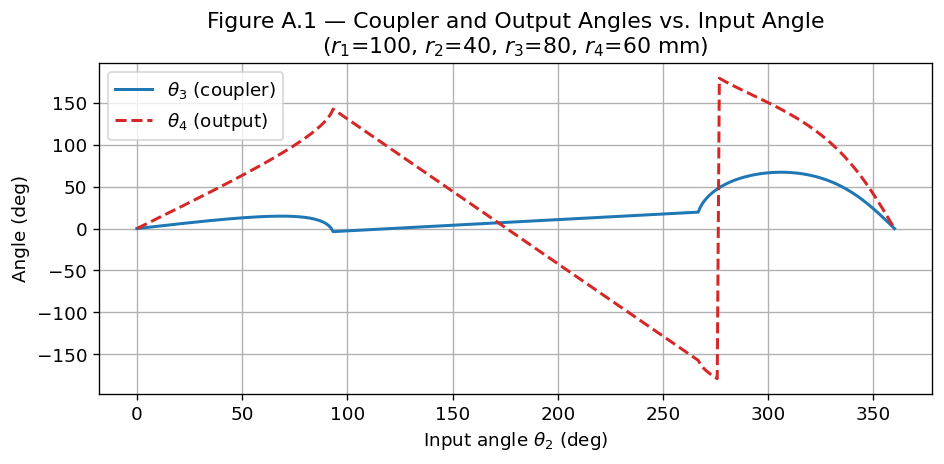

Figure A.1 saved.


In [5]:
from numpy import *
import matplotlib.pyplot as plt

# ── Plot theta3 and theta4 vs theta2 ──
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rad2deg(theta2[valid]), rad2deg(theta3[valid]),
        label=r"$\theta_3$ (coupler)", color="#1f77b4", lw=1.8)
ax.plot(rad2deg(theta2[valid]), rad2deg(theta4[valid]),
        label=r"$\theta_4$ (output)", color="#d62728", lw=1.8, ls="--")
ax.set_xlabel(r"Input angle $\theta_2$ (deg)")
ax.set_ylabel("Angle (deg)")
ax.set_title("Figure A.1 — Coupler and Output Angles vs. Input Angle\n"
             r"($r_1$=100, $r_2$=40, $r_3$=80, $r_4$=60 mm)")
ax.legend()
plt.tight_layout()
plt.savefig("fig_A1_angles_vs_theta2.png", dpi=150)
plt.show()
print("Figure A.1 saved.")

---
## A.4 Grashof Condition — Theory and Verification

The **Grashof condition** determines whether at least one link can perform a
full 360° rotation relative to another link.

Let $S$, $L$, $P$, $Q$ denote the shortest, longest, and remaining two link lengths.
The condition is:

$$S + L \leq P + Q \quad \Rightarrow \quad \text{Grashof mechanism}$$

| Grashof? | Shortest link is... | Mechanism type |
|----------|---------------------|----------------|
| Yes | Link 1 (ground) | Double-crank |
| Yes | Link 2 (input) | Crank-rocker |
| Yes | Link 4 (output) | Rocker-crank |
| Yes | Link 3 (coupler) | Double-rocker |
| No | Any | Non-Grashof (triple-rocker) |


In [6]:
from numpy import *

def grashof_check(r1, r2, r3, r4):
    """Return Grashof classification for a four-bar mechanism.

    Parameters
    ----------
    r1, r2, r3, r4 : float – link lengths (ground, crank, coupler, rocker)

    Returns
    -------
    is_grashof : bool
    mechanism_type : str
    """
    lengths = array([r1, r2, r3, r4])
    S = lengths.min()           # shortest link
    L = lengths.max()           # longest link
    remaining = lengths[(lengths != S) & (lengths != L)]
    if len(remaining) < 2:
        remaining = sort(lengths)[1:3]  # handle ties
    P, Q = remaining[0], remaining[1]

    is_grashof = (S + L) <= (P + Q)
    idx_S = argmin(lengths)     # which link is shortest

    if is_grashof:
        types = {0: "Double-crank", 1: "Crank-rocker",
                 2: "Double-rocker (coupler shortest)",
                 3: "Rocker-crank"}
        mtype = types.get(idx_S, "Grashof")
    else:
        mtype = "Non-Grashof (triple-rocker)"

    return bool(is_grashof), mtype

# ── Test cases ──
test_cases = [
    (100, 40, 80, 60,  "Crank-rocker expected"),
    (40,  100, 80, 60, "Double-crank expected"),
    (120, 100, 90, 80, "Non-Grashof expected"),
]
print("  Lengths                    Grashof  Type")
print("-" * 65)
for r1, r2, r3, r4, label in test_cases:
    ok, t = grashof_check(r1, r2, r3, r4)
    tag = "Yes" if ok else "No"
    print(f"r=[{r1:3.0f},{r2:3.0f},{r3:3.0f},{r4:3.0f}]  {tag:>8}  {t}  <- {label}")

  Lengths                    Grashof  Type
-----------------------------------------------------------------
r=[100, 40, 80, 60]       Yes  Crank-rocker  <- Crank-rocker expected
r=[ 40,100, 80, 60]       Yes  Double-crank  <- Double-crank expected
r=[120,100, 90, 80]        No  Non-Grashof (triple-rocker)  <- Non-Grashof expected


---
## A.5 Position, Velocity and Acceleration Analysis

### A.5.1 Velocity Analysis

Differentiating the loop closure equation with respect to time:

$$\omega_3 = \dot{\theta}_3, \qquad \omega_4 = \dot{\theta}_4$$

The velocity relationships in matrix form are:

$$\begin{bmatrix} r_3 \sin\theta_3 & -r_4 \sin\theta_4 \\ -r_3 \cos\theta_3 & r_4 \cos\theta_4 \end{bmatrix}\begin{bmatrix} \omega_3 \\ \omega_4 \end{bmatrix} =\omega_2 \begin{bmatrix} r_2 \sin\theta_2 \\ -r_2 \cos\theta_2 \end{bmatrix}$$

### A.5.2 Acceleration Analysis

The angular accelerations $\alpha_3 = \ddot{\theta}_3$, $\alpha_4 = \ddot{\theta}_4$
are obtained from the second derivative of the loop closure:

$$\begin{bmatrix} r_3 \sin\theta_3 & -r_4 \sin\theta_4 \\ -r_3 \cos\theta_3 & r_4 \cos\theta_4 \end{bmatrix}\begin{bmatrix} \alpha_3 \\ \alpha_4 \end{bmatrix} = \mathbf{b}_{\alpha}$$

where $\mathbf{b}_{\alpha}$ collects centripetal terms:

$$b_{\alpha,x} = \omega_2^2 r_2 \cos\theta_2 + \omega_3^2 r_3 \cos\theta_3 - \omega_4^2 r_4 \cos\theta_4$$
$$b_{\alpha,y} = \omega_2^2 r_2 \sin\theta_2 + \omega_3^2 r_3 \sin\theta_3 - \omega_4^2 r_4 \sin\theta_4$$


In [15]:
from numpy import *

def velocity_analysis(r2, r3, r4, theta2, theta3, theta4, omega2):
    """Compute omega3, omega4 via the velocity loop equation."""
    A_mat = array([
        [ r3 * sin(theta3), -r4 * sin(theta4)],
        [-r3 * cos(theta3),  r4 * cos(theta4)]
    ])
    b_vec = omega2 * array([
         r2 * sin(theta2),
        -r2 * cos(theta2)
    ])
    try:
        omega3, omega4 = linalg.solve(A_mat, b_vec)
    except linalg.LinAlgError:
        omega3, omega4 = nan, nan
    return omega3, omega4


def acceleration_analysis(r2, r3, r4, theta2, theta3, theta4,
                           omega2, omega3, omega4, alpha2=0.0):
    """Compute alpha3, alpha4 via the acceleration loop equation."""
    if isnan(omega3) or len(array([omega3]).flatten()) == 0:
        return nan, nan
    A_mat = array([
        [ r3 * sin(theta3), -r4 * sin(theta4)],
        [-r3 * cos(theta3),  r4 * cos(theta4)]
    ])
    bx = (alpha2  * r2 * sin(theta2) + omega2**2 * r2 * cos(theta2)
        + omega3**2 * r3 * cos(theta3) - omega4**2 * r4 * cos(theta4))
    by = (-alpha2 * r2 * cos(theta2) + omega2**2 * r2 * sin(theta2)
        + omega3**2 * r3 * sin(theta3) - omega4**2 * r4 * sin(theta4))
    try:
        alpha3, alpha4 = linalg.solve(A_mat, array([bx, by]))
    except linalg.LinAlgError:
        alpha3, alpha4 = nan, nan
    return alpha3, alpha4

# ── Full kinematic sweep ──
r1, r2, r3, r4 = 100.0, 40.0, 80.0, 60.0
omega2 = 2 * pi          # 1 rev/s = 2π rad/s
theta2_arr = linspace(0, 2 * pi, 360)
theta3_arr, theta4_arr, valid = freudenstein_solve(r1, r2, r3, r4, theta2_arr)

omega3_arr  = full(360, nan)
omega4_arr  = full(360, nan)
alpha3_arr  = full(360, nan)
alpha4_arr  = full(360, nan)

for i in where(valid)[0]:
    omega3_arr[i], omega4_arr[i] = velocity_analysis(
        r2, r3, r4, theta2_arr[i], theta3_arr[i], theta4_arr[i], omega2)
    alpha3_arr[i], alpha4_arr[i] = acceleration_analysis(
        r2, r3, r4, theta2_arr[i], theta3_arr[i], theta4_arr[i],
        omega2, omega3_arr[i], omega4_arr[i])

valid_vel = valid & ~isnan(omega4_arr)
print(f"omega4 range: [{nanmin(omega4_arr[valid_vel]):.2f}, {nanmax(omega4_arr[valid_vel]):.2f}] rad/s")
print(f"alpha4 range: [{nanmin(alpha4_arr[valid_vel]):.2f}, {nanmax(alpha4_arr[valid_vel]):.2f}] rad/s²")

omega4 range: [-71.27, 28.09] rad/s
alpha4 range: [-271301004810375648.00, 160446.32] rad/s²


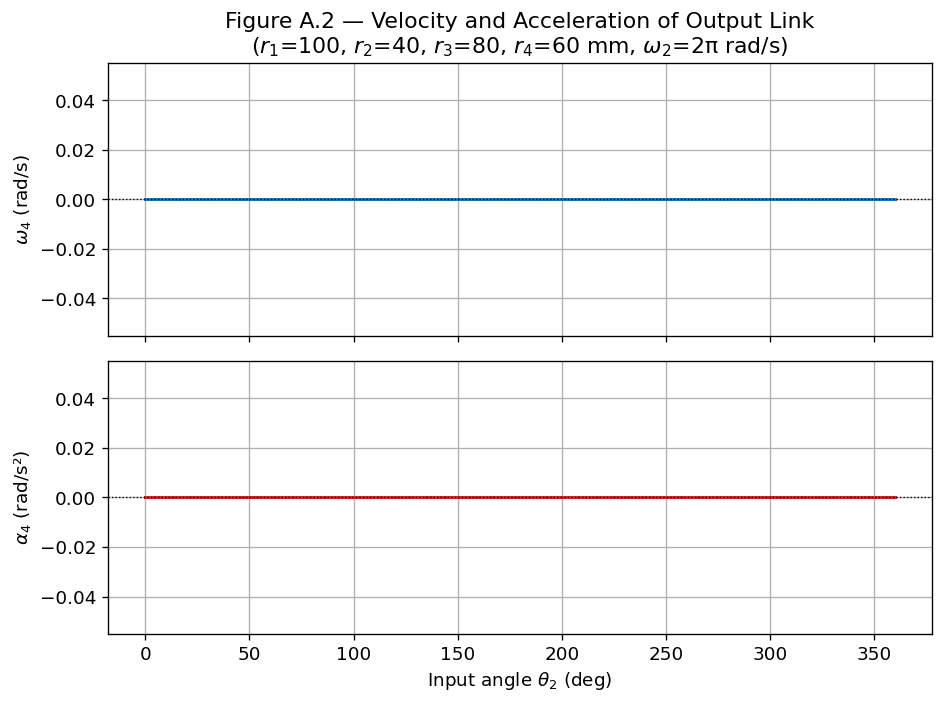

Figure A.2 saved.


In [8]:
from numpy import *
import matplotlib.pyplot as plt

# ── Plot velocity and acceleration of output link ──
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(rad2deg(theta2_arr[valid]), omega4_arr[valid],
             color="#1f77b4", lw=1.8)
axes[0].set_ylabel(r"$\omega_4$ (rad/s)")
axes[0].set_title("Figure A.2 — Velocity and Acceleration of Output Link\n"
                  r"($r_1$=100, $r_2$=40, $r_3$=80, $r_4$=60 mm, $\omega_2$=2π rad/s)")

axes[1].plot(rad2deg(theta2_arr[valid]), alpha4_arr[valid],
             color="#d62728", lw=1.8)
axes[1].set_ylabel(r"$\alpha_4$ (rad/s²)")
axes[1].set_xlabel(r"Input angle $\theta_2$ (deg)")

for ax in axes:
    ax.axhline(0, color="k", lw=0.8, ls=":")

plt.tight_layout()
plt.savefig("fig_A2_velocity_acceleration.png", dpi=150)
plt.show()
print("Figure A.2 saved.")

---
## A.6 Transmission Angle Analysis

The **transmission angle** $\mu$ is the angle between the coupler (link 3) and
the output link (link 4). It measures the quality of force transmission:

$$\mu = |\theta_3 - \theta_4|$$

Good force transmission requires $\mu \in [45°,\, 135°]$.
The **deviation** from the ideal 90° is:

$$\Delta\mu = |\mu - 90°|$$

A synthesized mechanism is acceptable if $\Delta\mu \leq 45°$ for the entire cycle.


Transmission angle range: [0.0°, 89.9°]
Minimum mu: 0.0°  (optimal >= 40°)
Fraction of cycle in acceptable zone (μ≥40°): 59.6%


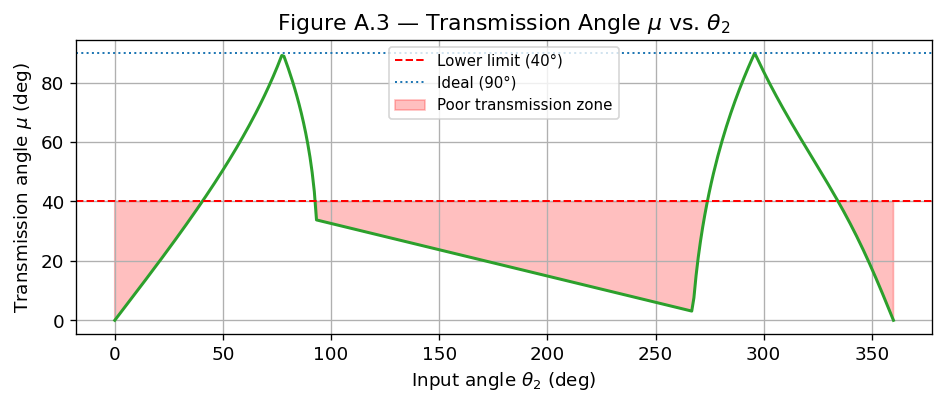

Figure A.3 saved.


In [9]:
from numpy import *
import matplotlib.pyplot as plt

def transmission_angle(theta3_arr, theta4_arr):
    """Return |theta3 - theta4| in degrees (wrapped to [0, 90])."""
    mu = abs(theta3_arr - theta4_arr)
    # Map to [0°, 90°] for symmetry
    mu = where(mu > pi, 2 * pi - mu, mu)
    mu = where(mu > pi / 2, pi - mu, mu)
    return rad2deg(mu)

mu_arr = transmission_angle(theta3_arr, theta4_arr)
mu_valid = mu_arr[valid]

print(f"Transmission angle range: [{mu_valid.min():.1f}°, {mu_valid.max():.1f}°]")
print(f"Minimum mu: {mu_valid.min():.1f}°  (optimal >= 40°)")
frac_ok = (mu_valid >= 40).mean() * 100
print(f"Fraction of cycle in acceptable zone (μ≥40°): {frac_ok:.1f}%")

# ── Plot ──
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(rad2deg(theta2_arr[valid]), mu_valid, color="#2ca02c", lw=1.8)
ax.axhline(40, color="red",    ls="--", lw=1.2, label="Lower limit (40°)")
ax.axhline(90, color="#1f77b4", ls=":",  lw=1.2, label="Ideal (90°)")
ax.fill_between(rad2deg(theta2_arr[valid]), mu_valid, 40,
                where=mu_valid < 40, alpha=0.25, color="red",
                label="Poor transmission zone")
ax.set_xlabel(r"Input angle $\theta_2$ (deg)")
ax.set_ylabel(r"Transmission angle $\mu$ (deg)")
ax.set_title(r"Figure A.3 — Transmission Angle $\mu$ vs. $\theta_2$")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("fig_A3_transmission_angle.png", dpi=150)
plt.show()
print("Figure A.3 saved.")

---
## A.7 Coupler Curve Generation

The **coupler point** $P$ is a fixed point on the coupler link defined by
its distance $r_p$ from joint $B$ at angle $\delta$ relative to the coupler:

$$P_x = r_2 \cos\theta_2 + r_p \cos(\theta_3 + \delta)$$
$$P_y = r_2 \sin\theta_2 + r_p \sin(\theta_3 + \delta)$$


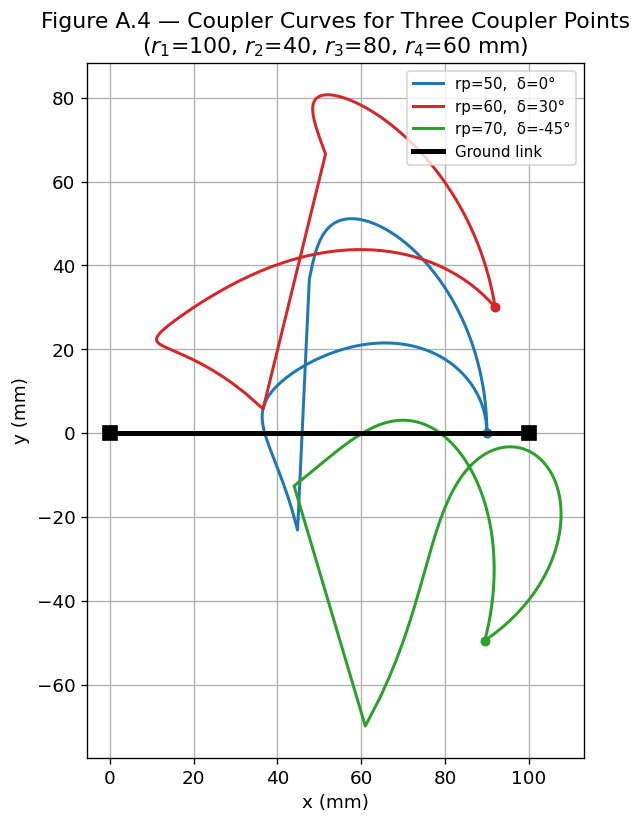

Figure A.4 saved.


In [10]:
from numpy import *
import matplotlib.pyplot as plt

def coupler_curve(r1, r2, r3, r4, rp, delta_deg, theta2_arr):
    """Compute the coupler-point trajectory.

    Parameters
    ----------
    rp        : float  – coupler point distance from joint B [same units as r]
    delta_deg : float  – coupler point angle relative to link 3 [degrees]
    """
    theta3, theta4, valid = freudenstein_solve(r1, r2, r3, r4, theta2_arr)
    delta = deg2rad(delta_deg)

    Px = r2 * cos(theta2_arr) + rp * cos(theta3 + delta)
    Py = r2 * sin(theta2_arr) + rp * sin(theta3 + delta)

    return Px[valid], Py[valid], valid

# ── Three coupler points with different (rp, delta) ──
r1, r2, r3, r4 = 100.0, 40.0, 80.0, 60.0
theta2 = linspace(0, 2 * pi, 360)

configs = [
    (50,   0,  "#1f77b4", "rp=50,  δ=0°"),
    (60,  30,  "#d62728", "rp=60,  δ=30°"),
    (70, -45,  "#2ca02c", "rp=70,  δ=-45°"),
]

fig, ax = plt.subplots(figsize=(7, 7))
for rp, delta, color, label in configs:
    Px, Py, _ = coupler_curve(r1, r2, r3, r4, rp, delta, theta2)
    ax.plot(Px, Py, color=color, lw=1.8, label=label)
    ax.plot(Px[0], Py[0], "o", color=color, ms=5)

# Draw ground link
ax.plot([0, r1], [0, 0], "k-", lw=3, label="Ground link")
ax.plot([0, r1], [0, 0], "ks", ms=8)

ax.set_aspect("equal")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.set_title("Figure A.4 — Coupler Curves for Three Coupler Points\n"
             r"($r_1$=100, $r_2$=40, $r_3$=80, $r_4$=60 mm)")
ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()
plt.savefig("fig_A4_coupler_curves.png", dpi=150)
plt.show()
print("Figure A.4 saved.")

---
## A.8 Reusable Genetic Algorithm Template

This self-contained GA function is used throughout the book.
Replace `fitness_fn` with any minimization objective.


In [11]:
from numpy import *

def genetic_algorithm(
        fitness_fn,
        n_vars,
        lb, ub,
        pop_size=100,
        n_gen=200,
        p_cross=0.8,
        p_mut=0.05,
        seed=None):
    """Minimization GA — real-valued encoding, tournament selection.

    Parameters
    ----------
    fitness_fn : callable(x) -> float
    n_vars     : int   – number of decision variables
    lb, ub     : float or array-like – lower / upper bounds
    pop_size   : int   – population size
    n_gen      : int   – number of generations
    p_cross    : float – crossover probability (BLX-α)
    p_mut      : float – mutation probability per gene
    seed       : int   – random seed for reproducibility

    Returns
    -------
    best_x    : ndarray  – best individual found
    best_fit  : float    – best fitness value
    history   : list     – best fitness per generation
    """
    rng = random.default_rng(seed)
    lb = broadcast_to(asarray(lb, float), n_vars).copy()
    ub = broadcast_to(asarray(ub, float), n_vars).copy()

    # ── Initialization ──
    pop = rng.uniform(lb, ub, (pop_size, n_vars))
    fit = array([fitness_fn(ind) for ind in pop])

    history = []

    for gen in range(n_gen):
        # ── Tournament selection (2-way) ──
        idx_a = rng.integers(0, pop_size, pop_size)
        idx_b = rng.integers(0, pop_size, pop_size)
        parents_idx = where(fit[idx_a] <= fit[idx_b], idx_a, idx_b)
        parents = pop[parents_idx]

        # ── BLX-α crossover ──
        offspring = parents.copy()
        alpha = 0.3
        for i in range(0, pop_size - 1, 2):
            if rng.random() < p_cross:
                lo = minimum(parents[i], parents[i+1]) - alpha * abs(parents[i] - parents[i+1])
                hi = maximum(parents[i], parents[i+1]) + alpha * abs(parents[i] - parents[i+1])
                offspring[i] = clip(rng.uniform(lo, hi), lb, ub)
                offspring[i+1] = clip(rng.uniform(lo, hi), lb, ub)

        # ── Gaussian mutation ──
        mask = rng.random(offspring.shape) < p_mut
        noise = rng.normal(0, 0.02 * (ub - lb), offspring.shape)
        offspring = clip(offspring + mask * noise, lb, ub)

        # ── Evaluate and elitism ──
        new_fit = array([fitness_fn(ind) for ind in offspring])
        best_idx = argmin(fit)
        worst_new = argmax(new_fit)
        offspring[worst_new] = pop[best_idx]   # preserve elite
        new_fit[worst_new] = fit[best_idx]

        pop, fit = offspring, new_fit
        history.append(float(fit.min()))

    best_idx = argmin(fit)
    return pop[best_idx], fit[best_idx], history

# ── Quick test: minimize Rosenbrock function ──
def rosenbrock(x):
    """Rosenbrock benchmark: minimum at x=(1,1,...), f=0."""
    return sum(100 * (x[1:] - x[:-1]**2)**2 + (1 - x[:-1])**2)

best_x, best_f, hist = genetic_algorithm(
    rosenbrock, n_vars=4, lb=-2, ub=2,
    pop_size=100, n_gen=300, seed=42)

print(f"Best solution: {best_x}")
print(f"Best fitness : {best_f:.6f}  (ideal = 0)")

Best solution: [0.72537818 0.53253255 0.28404148 0.07615127]
Best fitness : 0.812654  (ideal = 0)


---
## A.9 Reusable Neural Network Template (NumPy only)

A fully-connected MLP with configurable layers, ReLU activations, and
gradient-descent training — entirely in NumPy.


In [12]:
from numpy import *

class MLP:
    """Multi-layer perceptron (pure NumPy).

    Architecture : input → [hidden layers with ReLU] → output (linear)
    Loss         : mean squared error (MSE)
    Optimizer    : mini-batch stochastic gradient descent with momentum
    """

    def __init__(self, layer_sizes, seed=0):
        """Parameters
        ----------
        layer_sizes : list[int] – e.g. [4, 32, 32, 2] means
                       4 inputs, two hidden layers of 32, 2 outputs
        """
        rng = random.default_rng(seed)
        self.W, self.b = [], []
        for i in range(len(layer_sizes) - 1):
            fan_in = layer_sizes[i]
            scale = sqrt(2.0 / fan_in)          # He initialization
            self.W.append(rng.normal(0, scale, (layer_sizes[i], layer_sizes[i+1])))
            self.b.append(zeros(layer_sizes[i+1]))
        self.n_layers = len(self.W)

    def _relu(self, z):
        return maximum(0, z)

    def _relu_grad(self, z):
        return (z > 0).astype(float)

    def forward(self, X):
        """Forward pass; stores activations for backprop."""
        self._a = [X]
        self._z = []
        for k, (W, b) in enumerate(zip(self.W, self.b)):
            z = self._a[-1] @ W + b
            self._z.append(z)
            a = self._relu(z) if k < self.n_layers - 1 else z  # output linear
            self._a.append(a)
        return self._a[-1]

    def loss(self, X, y):
        y_hat = self.forward(X)
        return mean((y_hat - y)**2)

    def backward(self, X, y, lr=1e-3, momentum=0.9):
        """One gradient-descent step with momentum."""
        if not hasattr(self, "_vW"):
            self._vW = [zeros_like(W) for W in self.W]
            self._vb = [zeros_like(b) for b in self.b]

        y_hat = self.forward(X)
        delta = 2 * (y_hat - y) / len(X)          # dL/d(output)

        for k in range(self.n_layers - 1, -1, -1):
            if k < self.n_layers - 1:
                delta = delta * self._relu_grad(self._z[k])
            dW = self._a[k].T @ delta
            db = delta.sum(axis=0)
            delta = delta @ self.W[k].T
            self._vW[k] = momentum * self._vW[k] - lr * dW
            self._vb[k] = momentum * self._vb[k] - lr * db
            self.W[k] += self._vW[k]
            self.b[k] += self._vb[k]

    def fit(self, X, y, epochs=500, lr=1e-3, batch=32, verbose=100):
        """Training loop."""
        n = len(X)
        history = []
        for ep in range(1, epochs + 1):
            idx = random.permutation(n)
            for start in range(0, n, batch):
                b = idx[start:start+batch]
                self.backward(X[b], y[b], lr=lr)
            l = self.loss(X, y)
            history.append(l)
            if verbose and ep % verbose == 0:
                print(f"  Epoch {ep:4d}  MSE = {l:.6f}")
        return history

# ── Test: learn the sine function ──
X_train = linspace(-pi, pi, 400).reshape(-1, 1)
y_train = sin(X_train)

model = MLP([1, 32, 32, 1], seed=42)
hist = model.fit(X_train, y_train, epochs=1000, lr=3e-3, verbose=500)

y_pred = model.forward(X_train)
mse_final = mean((y_pred - y_train)**2)
print(f"Final MSE: {mse_final:.2e}  (target < 1e-3)")

  Epoch  500  MSE = 0.000250
  Epoch 1000  MSE = 0.000113
Final MSE: 1.13e-04  (target < 1e-3)


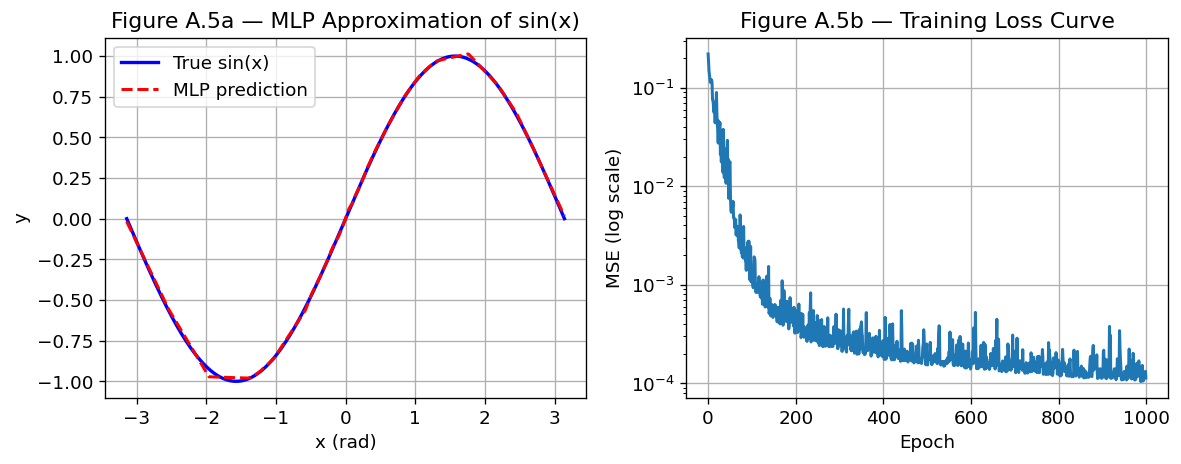

Figure A.5 saved.


In [13]:
from numpy import *
import matplotlib.pyplot as plt

# ── Plot: true sine vs MLP prediction ──
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(X_train, y_train, "b-",  lw=2,   label="True sin(x)")
axes[0].plot(X_train, y_pred,  "r--", lw=1.8, label="MLP prediction")
axes[0].set_xlabel("x (rad)")
axes[0].set_ylabel("y")
axes[0].set_title("Figure A.5a — MLP Approximation of sin(x)")
axes[0].legend()

axes[1].semilogy(hist, color="#1f77b4", lw=1.8)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE (log scale)")
axes[1].set_title("Figure A.5b — Training Loss Curve")

plt.tight_layout()
plt.savefig("fig_A5_mlp_sine.png", dpi=150)
plt.show()
print("Figure A.5 saved.")

---
## A.10 Quick Reference Tables

### A.10.1 NumPy Functions Used in This Book

| Function | Description | Example |
|----------|-------------|--------|
| `linspace(a,b,n)` | n evenly spaced values from a to b | `linspace(0, 2*pi, 360)` |
| `deg2rad(x)` | degrees → radians | `deg2rad(45)` → `0.7854` |
| `rad2deg(x)` | radians → degrees | `rad2deg(pi)` → `180.0` |
| `arctan2(y,x)` | four-quadrant arctangent | `arctan2(1,1)` → `π/4` |
| `linalg.solve(A,b)` | solve linear system A·x = b | velocity/accel. analysis |
| `random.default_rng(s)` | reproducible RNG | GA initialization |
| `where(cond,a,b)` | element-wise conditional | `where(mu<40,…)` |
| `broadcast_to(arr,shape)` | broadcast without copy | GA bounds |
| `clip(arr, lo, hi)` | element-wise clamp | mutation, bounds |

### A.10.2 Design Variable Bounds Recommended in the Book

| Variable | Lower bound | Upper bound | Unit |
|----------|-------------|-------------|------|
| $r_1$ (ground) | 50 | 200 | mm |
| $r_2$ (crank) | 20 | 120 | mm |
| $r_3$ (coupler) | 30 | 180 | mm |
| $r_4$ (rocker) | 30 | 180 | mm |
| $r_p$ (coupler point) | 10 | 150 | mm |
| $\delta$ (coupler point angle) | −180° | 180° | deg |

### A.10.3 GA Hyperparameter Guidelines

| Hyperparameter | Recommended range | Typical value |
|----------------|-------------------|---------------|
| Population size | 50 – 300 | 100 |
| Generations | 100 – 500 | 200 |
| Crossover probability | 0.6 – 0.9 | 0.8 |
| Mutation probability (per gene) | 0.01 – 0.1 | 0.05 |
| BLX-α parameter | 0.1 – 0.5 | 0.3 |
| Elite size | 1 – 5 | 1 |

### A.10.4 Transmission Angle Quality Criteria

| $\mu_{\min}$ | Quality | Recommendation |
|-------------|---------|----------------|
| ≥ 50° | Excellent | Preferred for high-speed applications |
| 40°–50° | Acceptable | Suitable for most applications |
| 30°–40° | Marginal | Use only for low-force, low-speed |
| < 30° | Poor | Avoid — high internal forces |


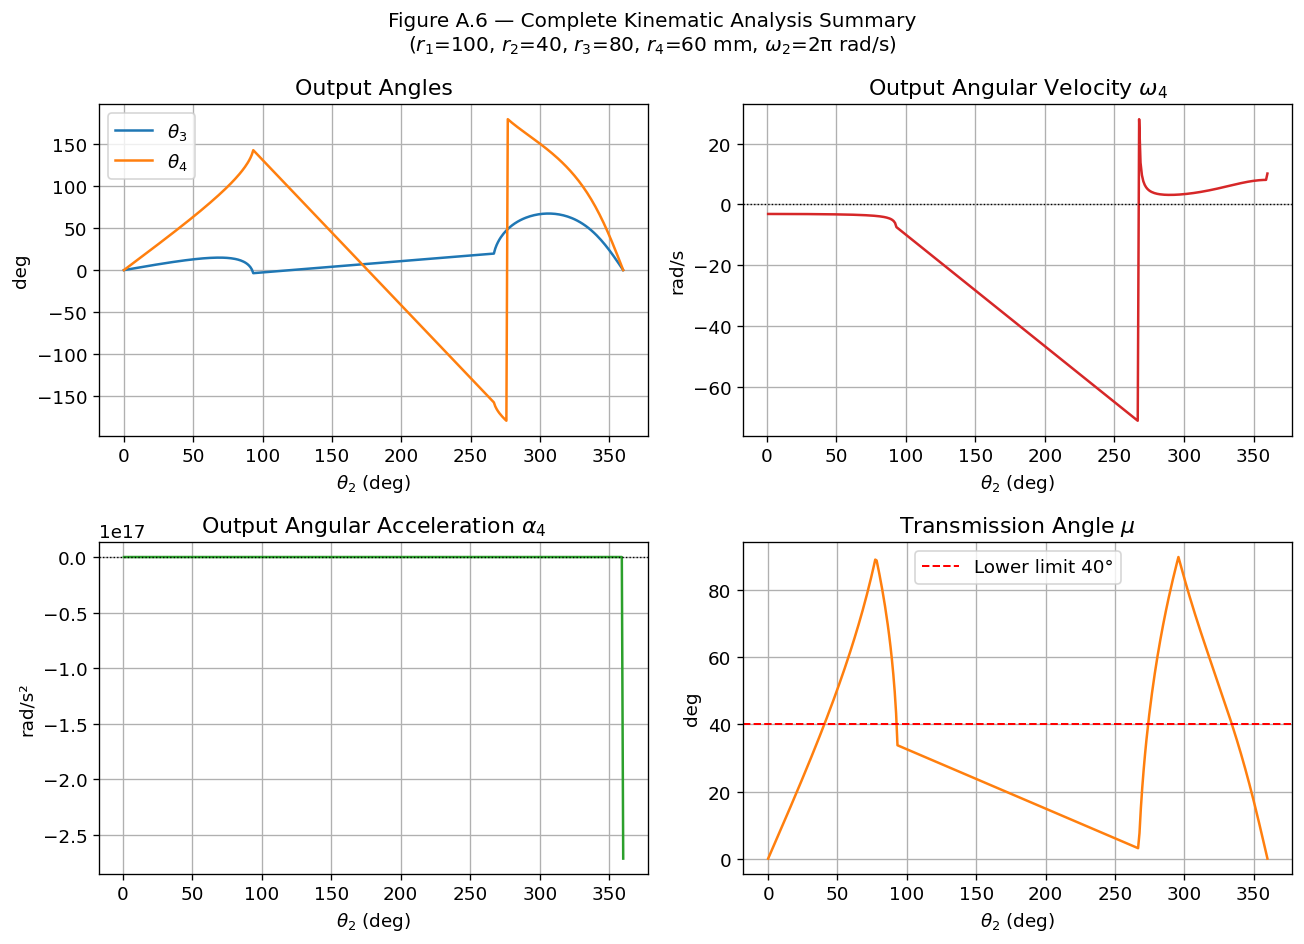

Figure A.6 — Complete kinematic analysis summary saved.


In [16]:
from numpy import *
import matplotlib.pyplot as plt

# ── Summary figure: complete kinematic analysis ──
r1, r2, r3, r4 = 100.0, 40.0, 80.0, 60.0
theta2 = linspace(0, 2 * pi, 360)
theta3_arr, theta4_arr, valid = freudenstein_solve(r1, r2, r3, r4, theta2)

omega2 = 2 * pi
omega3_arr = full(360, nan)
omega4_arr = full(360, nan)
alpha3_arr = full(360, nan)
alpha4_arr = full(360, nan)

for i in where(valid)[0]:
    omega3_arr[i], omega4_arr[i] = velocity_analysis(
        r2, r3, r4, theta2[i], theta3_arr[i], theta4_arr[i], omega2)
    alpha3_arr[i], alpha4_arr[i] = acceleration_analysis(
        r2, r3, r4, theta2[i], theta3_arr[i], theta4_arr[i],
        omega2, omega3_arr[i], omega4_arr[i])

mu_arr = transmission_angle(theta3_arr, theta4_arr)
th2d = rad2deg(theta2[valid])

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].plot(th2d, rad2deg(theta3_arr[valid]), label=r"$\theta_3$")
axes[0, 0].plot(th2d, rad2deg(theta4_arr[valid]), label=r"$\theta_4$")
axes[0, 0].set_title("Output Angles")
axes[0, 0].set_ylabel("deg")
axes[0, 0].legend()

axes[0, 1].plot(th2d, omega4_arr[valid], color="#d62728")
axes[0, 1].axhline(0, color="k", lw=0.8, ls=":")
axes[0, 1].set_title(r"Output Angular Velocity $\omega_4$")
axes[0, 1].set_ylabel("rad/s")

axes[1, 0].plot(th2d, alpha4_arr[valid], color="#2ca02c")
axes[1, 0].axhline(0, color="k", lw=0.8, ls=":")
axes[1, 0].set_title(r"Output Angular Acceleration $\alpha_4$")
axes[1, 0].set_ylabel("rad/s²")

axes[1, 1].plot(th2d, mu_arr[valid], color="#ff7f0e")
axes[1, 1].axhline(40, color="red", ls="--", lw=1.2, label="Lower limit 40°")
axes[1, 1].set_title(r"Transmission Angle $\mu$")
axes[1, 1].set_ylabel("deg")
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel(r"$\theta_2$ (deg)")

fig.suptitle("Figure A.6 — Complete Kinematic Analysis Summary\n"
             r"($r_1$=100, $r_2$=40, $r_3$=80, $r_4$=60 mm, $\omega_2$=2π rad/s)",
             fontsize=12)
plt.tight_layout()
plt.savefig("fig_A6_complete_analysis.png", dpi=150)
plt.show()
print("Figure A.6 — Complete kinematic analysis summary saved.")

---

## End of Appendix A

**Summary of functions defined in this notebook:**

| Function | Returns | Used in |
|----------|---------|--------|
| `freudenstein_solve(r1,r2,r3,r4, theta2)` | θ₃, θ₄, valid | Chapters 1–16 |
| `grashof_check(r1,r2,r3,r4)` | is_grashof, type | Chapters 1, 5, 6 |
| `velocity_analysis(...)` | ω₃, ω₄ | Chapters 2, 5 |
| `acceleration_analysis(...)` | α₃, α₄ | Chapter 2 |
| `transmission_angle(θ₃, θ₄)` | μ [deg] | Chapters 1, 5, 6 |
| `coupler_curve(r1,r2,r3,r4, rp,δ, θ₂)` | Px, Py | Chapters 1–10 |
| `genetic_algorithm(fitness_fn, ...)` | best_x, best_f, history | Chapters 3–10 |
| `MLP(layer_sizes)` | trained model | Chapters 4, 7, 13, 14 |

> **File:** `appendix_A_numpy_math_reference.ipynb`  
> **Book:** *Four-Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks*
